# Figure 4 — PANCAN evaluation and generalization (+ the assembled Figure S16)

Figure 4:
- (a) nested-CV mean ROC, healthy vs all seven cancer types (PANCAN, Cristiano cohort);
- (b) Jiang cohort, HCC vs all 135 non-HCC, 32 healthy, 67 chronic hepatitis B and 36 HBV cirrhosis: AUROC
  (participant bootstrap CIs) of the Cristiano-trained models applied once to Jiang (data-driven, ATAC, RNA)
  next to the data-driven model trained within Jiang (fully nested, pooled out-of-fold);
- (c) AUROC on Jiang against the number of selected TSSs: Cristiano-trained per-k models vs the k-sweep
  trained within Jiang;
- (d, e) leave-one-cancer-type-out: (d) AUROC per left-out type next to the same samples in the nested CV;
  (e) AUROC when one fixed model uses only the best-scoring TSSs. Details and the score distributions are
  in `fig4_loco.ipynb`.

Figure S16 (assembled at the end): (a) AUROC per Jiang comparison group of the TSS model, the same model
standardised on Jiang ('clinical' deployment), the five cohort-transferable covariates inside the model
and alone, the RNA and ATAC comparators and each covariate alone; (b) ROC on Jiang, HCC vs all non-HCC.

Source data in `data/<cohort>/` (default `data/no_deep/`), written by `export/export_fig4.py` unless noted:
- `fig4a_predictions.csv`, `fig4a_config.csv` — PANCAN out-of-fold predictions (ichorCNA rows carry the
  tumor fraction; `n_rows_in_source` = row multiplicity of the ichorCNA table);
- `fig4bc_external_predictions.csv`, `fig4bc_config.csv`, `fig4bc_fixed_threshold.csv` — deployed
  Cristiano models on Jiang, with the 95%-specificity threshold frozen on the training cohort
  (`threshold_95spec_train`, source in `threshold_95spec_train_source`);
- `fig4gi_jiang_nested_{oof,config}.csv` — fully nested runs trained within Jiang;
- `fig4j_auc_vs_k.csv` (+ `_predictions.csv`), `fig4j_jiang_ksweep.csv` (+ `_predictions.csv`) — panel c;
- `fig4kl_external_modes_{predictions,config}.csv` — pipeline vs clinical standardization on Jiang;
- `fig4_loco_{per_type,predictions,ksweep}.csv` (`export/export_fig4_loco.py`), `fig4_loco_rankings.csv`
  (`export/export_fig4_loco_rankings.py`), optional `fig4_loco_comparators.csv` (RNA/ATAC arms);
- `figS16_jiang_{summary,scores}.csv` (`export/export_figS16_jiang_arms.py --from_runs`).

Run top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch: "no_deep" (default) = without the 30 deep-sequenced healthy controls, "all" = full cohort.
# Set FIG_COHORT in the environment. Files a variant has not exported fall back to data/ with a notice.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import _figstyle as fs   # main-figure style; applied only around the Figure 4 drawing (Fig S16 keeps its own)
import matplotlib.ticker as mticker
from scipy.interpolate import interp1d
from scipy.stats import beta as beta_dist
from sklearn.metrics import roc_curve, auc, roc_auc_score

APPROACH_COLORS = {
    "RNA": "#CA3542", "ATAC": "#ECB22E",
    "Data-driven": "#0173B2", "ichorCNA": "#6A3D9A",
    "Data-driven (Jiang-trained)": "#7FB3D5",
}
METHOD_LABELS = {"data_driven": "Data-driven", "atac": "ATAC", "rna": "RNA",
                 "ichorcna": "ichorCNA", "dd": "Data-driven",
                 "dd_jiang": "Data-driven (Jiang-trained)"}

# Jiang comparison groups (Jiang et al. 2015): the 135 "controls" are three
# clinically distinct non-HCC groups, not 135 healthy people.
SUBGROUP_ORDER = ["Healthy", "Hepatitis B", "Cirrhosis", "Liver cancer"]
SUBGROUP_LABELS = {"Healthy": "Healthy", "Hepatitis B": "Chronic\nhepatitis B",
                   "Cirrhosis": "HBV\ncirrhosis", "Liver cancer": "HCC"}
SUBGROUP_COLORS = {"Healthy": "#2E8B57", "Hepatitis B": "#E69F00",
                   "Cirrhosis": "#B15928", "Liver cancer": "#0173B2"}
COMPARISONS = [("Healthy", "vs healthy"), ("Hepatitis B", "vs chronic HBV"),
               ("Cirrhosis", "vs cirrhosis"), ("all", "vs all non-HCC")]

pred5a = pd.read_csv(data_path("fig4a_predictions.csv"))
cfg5a = pd.read_csv(data_path("fig4a_config.csv"))
ext = pd.read_csv(data_path("fig4bc_external_predictions.csv"))
ext_cfg = pd.read_csv(data_path("fig4bc_config.csv")).set_index("method")
ext_fixed = pd.read_csv(data_path("fig4bc_fixed_threshold.csv"))
loco_type = pd.read_csv(data_path("fig4_loco_per_type.csv"))        # leave-one-cancer-type-out (export_fig4_loco.py)
loco_pred = pd.read_csv(data_path("fig4_loco_predictions.csv"))
loco_ks = pd.read_csv(data_path("fig4_loco_ksweep.csv"))            # the search's winner per k (not drawn; check cell)
loco_rank = pd.read_csv(data_path("fig4_loco_rankings.csv"))        # panel f (export_fig4_loco_rankings.py)
# RNA / ATAC comparator arms of the leave-one-out analysis (ARM=rna|atac slurm/submit_loco.sh);
# panel d draws whatever is exported
try:
    loco_comp = pd.read_csv(data_path("fig4_loco_comparators.csv"))
except FileNotFoundError:
    loco_comp = pd.DataFrame(columns=["arm", "type", "auc"])
jn_oof = pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv"))
jn_cfg = pd.read_csv(data_path("fig4gi_jiang_nested_config.csv"))
kc = pd.read_csv(data_path("fig4j_auc_vs_k.csv"))
kc_pred = pd.read_csv(data_path("fig4j_auc_vs_k_predictions.csv"))
jks = pd.read_csv(data_path("fig4j_jiang_ksweep.csv"))
jks_pred = pd.read_csv(data_path("fig4j_jiang_ksweep_predictions.csv"))
modes_pred = pd.read_csv(data_path("fig4kl_external_modes_predictions.csv"))
modes_cfg = pd.read_csv(data_path("fig4kl_external_modes_config.csv"))
HAVE_JIANG_NESTED = "hcc_vs_nonhcc" in set(jn_oof["task"])
s16_summary = pd.read_csv(data_path("figS16_jiang_summary.csv"))
s16_scores = pd.read_csv(data_path("figS16_jiang_scores.csv"))

assert ext.groupby("method")["subgroup"].value_counts().unstack().eq(
    pd.Series({"Healthy": 32, "Hepatitis B": 67, "Cirrhosis": 36, "Liver cancer": 90})).all().all(), \
    "Jiang comparison-group counts differ from Jiang et al. 2015"
display(cfg5a)
display(ext_cfg)
display(jn_cfg if len(jn_cfg) else "Jiang-trained nested run: pending (panels b/h/i fall back)")
display(modes_cfg if len(modes_cfg) else "external standardization modes: pending (panels k/l fall back)")
display(jks if len(jks) else "Jiang-trained k-sweep: pending (panel j shows the single nested-CV value)")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


,method,feature,classifier,weighting_function,top_genes,source_dir,selection_mean_auc,note
0,data_driven,griffin_diff,Logistic Regression,mean_diff,10000.0,nested_cv_results_cris/nested_full_pancan_nest...,0.969495,fully nested: config chosen per fold; modal sh...
1,rna,rcov,Random Forest,NaN,NaN,nested_cv_results_cris/pancan_rna_rev_nodeep,0.676022,fully nested: classifier per fold on inner CV ...
2,atac,ulz_atac_tfbs_features,Logistic Regression,NaN,NaN,nested_cv_results_cris/pancan_atac_rev_nodeep,0.896984,fully nested: classifier per fold on inner CV ...
3,ichorcna,ichorcna_tf,NaN,NaN,NaN,accessory_files/cris_stage_vaf_coverage_ichor.csv,NaN,NaN


,feature,classifier,n_genes,train_cv_auc,external_auc,threshold_95spec_external,threshold_95spec_train,threshold_95spec_train_source,proba_degenerate,source_dir
method,,,,,,,,,,
dd,griffin_diff,Logistic Regression,15000,0.972443,0.741152,0.573396,0.445077,training_inner_cv,False,nested_cv_results_cris/external_validation_com...
rna,rcov,Xgboost,781,0.735868,0.503128,0.971425,0.893664,training_inner_cv,False,nested_cv_results_cris/external_validation_com...
atac,ulz_atac_tfbs_features,Support Vector Machine,497,0.923668,0.470123,0.951673,0.787554,training_inner_cv,False,nested_cv_results_cris/external_validation_com...


,task,n_samples,n_hcc,n_control,control_groups,mean_test_auc,std_test_auc,oof_auc_pooled,modal_feature,modal_selection_type,modal_n_top_genes,modal_classifier,n_distinct_configs,source_dir
0,hcc_vs_nonhcc,225,90,135,Cirrhosis | Healthy | Hepatitis B,0.901893,0.076100,0.875062,griffin_diff,weighted,10000,Multi-Layer Perceptron,8,nested_cv_results_jiang/nested_full_jiang_hcc_...
1,hcc_vs_healthy,122,90,32,Healthy,0.928704,0.062044,0.816667,griffin_diff,mean_diff,10000,Multi-Layer Perceptron,8,nested_cv_results_jiang/nested_full_jiang_hcc_...


,mode,feature,classifier,n_genes,train_cv_auc,external_auc,threshold_95spec_train,threshold_95spec_train_source,proba_degenerate,source_dir
0,pipeline,griffin_diff,Logistic Regression,15000,0.972443,0.741152,0.445077,training_inner_cv,False,nested_cv_results_cris/external_validation_com...
1,clinical,griffin_diff,Logistic Regression,15000,0.972443,0.739753,0.445077,training_inner_cv,False,nested_cv_results_cris/external_validation_com...


,k,mean_test_auc,std_test_auc,oof_auc_pooled,mean_inner_score,modal_feature,modal_selection_type,n_distinct_configs,mean_num_genes_used,source_dir
0,10,0.613278,0.088426,0.582263,0.671842,fslr_coverage,p_value,9,10.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
1,25,0.575946,0.115840,0.569712,0.698175,fslr_coverage,p_value,7,25.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
2,50,0.644811,0.147772,0.637325,0.738199,fslr_coverage,p_value,8,50.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
3,100,0.735958,0.146362,0.714156,0.763203,fslr_coverage,p_value,6,100.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
4,250,0.710806,0.144499,0.708148,0.797329,fslr_coverage,p_value,9,250.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
5,500,0.776618,0.129000,0.743128,0.828817,griffin_diff,weighted,6,500.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
6,1000,0.771368,0.119529,0.755226,0.860034,griffin_diff,weighted,7,1000.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
7,1500,0.799328,0.128709,0.800823,0.866694,griffin_diff,weighted,7,1500.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
8,2500,0.858364,0.082999,0.832757,0.880535,griffin_diff,p_value,6,2500.0,nested_cv_results_jiang/nested_full_jiang_hcc_...
9,5000,0.867338,0.065731,0.814321,0.895715,griffin_diff,mean_diff,7,5000.0,nested_cv_results_jiang/nested_full_jiang_hcc_...


## Panel a — PANCAN nested-CV mean ROC

In [2]:
def expand(df):
    return df.loc[df.index.repeat(df["n_rows_in_source"])]


# method names of the main figures (_figstyle); METHOD_LABELS stays for the check cell and Fig S16
FS_NAME = {"data_driven": "Data-driven", "dd": "Data-driven", "atac": "ATAC-seq", "rna": "RNA-seq", "ichorcna": "ichorCNA"}


def panel_a(ax):
    base_fpr = np.linspace(0, 1, 101)
    for method in ["data_driven", "atac", "rna", "ichorcna"]:
        name = FS_NAME[method]
        color = fs.METHOD[name]
        df = pred5a[(pred5a["method"] == method) & pred5a["fold"].notna()]
        tprs, aucs = [], []
        for _, g in df.groupby("fold"):
            g = expand(g).dropna(subset=["score"])
            fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
            tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
            aucs.append(auc(fpr, tpr))
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0, 1
        std_tpr = np.std(tprs, axis=0)
        ax.plot(base_fpr, mean_tpr, color=color, linewidth=1.2,
                label=f"{name}: {np.mean(aucs):.3f} \u00b1 {np.std(aucs):.3f}")
        ax.fill_between(base_fpr, np.maximum(mean_tpr - std_tpr, 0),
                        np.minimum(mean_tpr + std_tpr, 1), color=color, alpha=0.15, linewidth=0)
    ax.plot([0, 1], [0, 1], color=fs.CHANCE, linestyle=":", linewidth=0.8)
    ax.axvline(x=0.05, color=fs.NEUTRAL, linestyle="--", linewidth=0.8, zorder=1)   # 95% specificity (caption)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.03)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", title="Mean AUROC \u00b1 SD", alignment="left", handlelength=1.0, handletextpad=0.4,
              labelspacing=0.15, borderpad=0.3, borderaxespad=0.2, frameon=True, framealpha=0.92, edgecolor="none")


## Panels b and c — application to the Jiang cohort

One deployed model per method, selected on training-CV AUC. ROCs use `score_for_roc`
(`decision_function` when Platt-scaled probabilities are degenerate). The operating point is the
95%-specificity threshold frozen on the Cristiano cohort (`threshold_95spec_train`), with Clopper–Pearson
95% CIs. `panel_b` (ROC) and `panel_c` (sensitivity at the frozen threshold) are not drawn in the assembled
figures; their numbers are printed in the check cell.

In [3]:
# Frozen-threshold provenance (fig4bc_config.csv). "training_inner_cv": held-out scores of the
# selected configuration on the best-model search's own folds; "training_oof": a separate
# 10-fold pass (drawn, but flagged).
FROZEN_THRESHOLD_SOURCES = ("training_inner_cv", "training_oof")
for _m, _src in ext_cfg["threshold_95spec_train_source"].items():
    if _src == "training_oof":
        print(f"!! {_m}: frozen threshold predates the inner-CV derivation (separate 10-fold "
              "pass) - refresh the best-model search and rerun the external validation "
              "before quoting panel c.")


def clopper_pearson(k, n, alpha=0.05):
    """Exact binomial CI for k successes in n."""
    if n == 0:
        return np.nan, np.nan
    lo = 0.0 if k == 0 else beta_dist.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta_dist.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)


ext_rocs = {}
for method in ["dd", "atac", "rna"]:
    g = ext[ext["method"] == method]
    fpr, tpr, thr = roc_curve(g["y_true"], g["score_for_roc"])
    ext_rocs[method] = {"fpr": fpr, "tpr": tpr, "auc": auc(fpr, tpr),
                        "sens_95_ext": tpr[np.argmin(np.abs(fpr - 0.05))]}

# Jiang-trained fully nested run: pooled out-of-fold ROC, HCC vs all non-HCC
if HAVE_JIANG_NESTED:
    jn = jn_oof[jn_oof["task"] == "hcc_vs_nonhcc"]
    fpr, tpr, _ = roc_curve(jn["y_true"], jn["score"])
    per_fold = [roc_auc_score(f["y_true"], f["score"]) for _, f in jn.groupby("outer_fold")]
    ext_rocs["dd_jiang"] = {"fpr": fpr, "tpr": tpr, "auc": auc(fpr, tpr),
                            "fold_mean": np.mean(per_fold), "fold_std": np.std(per_fold, ddof=1)}


def frozen_operating_point(method):
    """Sensitivity / specificity of HCC vs all non-HCC at the threshold frozen on
    the training cohort. Prefers the pipeline's own counts
    (fig4bc_fixed_threshold.csv); otherwise applies threshold_95spec_train to
    the exported probabilities. Returns None when no finite frozen threshold
    exists for this method (legacy summary) or its probabilities are degenerate."""
    row = ext_fixed[(ext_fixed["method"] == method)
                    & (ext_fixed["operating_point"] == "95_percent_specificity")
                    & (ext_fixed["comparison_group"] == "all_non_hcc")]
    if len(row):
        r = row.iloc[0]
        return {"sens": r["sensitivity"], "sens_ci": (r["sensitivity_ci_low"], r["sensitivity_ci_high"]),
                "spec": r["specificity"], "spec_ci": (r["specificity_ci_low"], r["specificity_ci_high"]),
                "tp": int(r["tp"]), "fn": int(r["fn"]), "tn": int(r["tn"]), "fp": int(r["fp"]),
                "threshold": r["threshold"], "source": "pipeline"}
    cfg = ext_cfg.loc[method]
    thr = cfg["threshold_95spec_train"]
    if not np.isfinite(thr) or cfg["threshold_95spec_train_source"] not in FROZEN_THRESHOLD_SOURCES \
            or bool(cfg["proba_degenerate"]):
        return None
    g = ext[ext["method"] == method]
    yhat = (g["score"].to_numpy() >= thr).astype(int)
    y = g["y_true"].to_numpy()
    tp, fn = int(((y == 1) & (yhat == 1)).sum()), int(((y == 1) & (yhat == 0)).sum())
    tn, fp = int(((y == 0) & (yhat == 0)).sum()), int(((y == 0) & (yhat == 1)).sum())
    return {"sens": tp / (tp + fn), "sens_ci": clopper_pearson(tp, tp + fn),
            "spec": tn / (tn + fp), "spec_ci": clopper_pearson(tn, tn + fp),
            "tp": tp, "fn": fn, "tn": tn, "fp": fp, "threshold": thr, "source": "notebook"}


frozen_ops = {m: frozen_operating_point(m) for m in ["dd", "atac", "rna"]}
# A frozen threshold that lands outside the external score range (specificity
# collapses to ~0 or sensitivity to ~0) means the probability SCALE did not
# transfer; the operating point is then reported as non-transferable rather
# than as a sensitivity.
NON_TRANSFERABLE_SPEC = 0.5


def panel_b(ax):
    for method in ["dd", "atac", "rna"]:
        d = ext_rocs[method]
        name = METHOD_LABELS[method]
        ax.plot(d["fpr"], d["tpr"], color=APPROACH_COLORS[name], linewidth=2.3,
                label=f"{name} — AUC = {d['auc']:.3f}")
    if "dd_jiang" in ext_rocs:
        d = ext_rocs["dd_jiang"]
        ax.plot(d["fpr"], d["tpr"], color=APPROACH_COLORS["Data-driven"], linewidth=2.3,
                linestyle="--",
                label=f"Data-driven, trained within Jiang\n(nested CV, pooled OOF) — AUC = {d['auc']:.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1.2)
    ax.axvline(x=0.05, color="dimgray", linestyle=":", linewidth=1.6, alpha=0.85,
               zorder=1, label="95% specificity (FPR = 0.05)")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel("False Positive Rate", fontsize=15)
    ax.set_ylabel("True Positive Rate", fontsize=15)
    ax.legend(loc="lower right", fontsize=10, frameon=True, framealpha=0.9,
              edgecolor="#cccccc")
    ax.tick_params(labelsize=12)


def panel_c(ax):
    methods = ["dd", "atac", "rna"]
    x = np.arange(len(methods))
    any_pending, any_nontransfer = False, False
    for xi, m in enumerate(methods):
        color = APPROACH_COLORS[METHOD_LABELS[m]]
        op = frozen_ops[m]
        desc = ext_rocs[m]["sens_95_ext"]
        if op is None or op["spec"] < NON_TRANSFERABLE_SPEC:
            # no usable frozen threshold: descriptive external-ROC operating point, hatched
            ax.bar(xi, desc, color=color, alpha=0.45, edgecolor="black", linewidth=0.6, hatch="//")
            ax.text(xi, desc + 0.03, f"{desc:.2f}", ha="center", va="bottom", fontsize=12,
                    fontweight="bold", color=color)
            if op is None:
                any_pending = True
                note = "frozen thr. pending"
            else:
                any_nontransfer = True
                note = f"frozen thr. {op['threshold']:.2f}:\nspec {op['spec']:.2f}, sens {op['sens']:.2f}\n(scale not transferable)"
            ax.text(xi, -0.08, note, ha="center", va="top", fontsize=8.5, color="dimgray",
                    transform=ax.get_xaxis_transform())
            continue
        lo, hi = op["sens_ci"]
        ax.bar(xi, op["sens"], color=color, alpha=0.85, edgecolor="black", linewidth=0.6)
        ax.errorbar(xi, op["sens"], yerr=[[op["sens"] - lo], [hi - op["sens"]]], fmt="none",
                    ecolor="black", elinewidth=1.2, capsize=5, capthick=1.2)
        ax.plot(xi, desc, marker="o", markersize=8, markerfacecolor="white",
                markeredgecolor=color, markeredgewidth=1.8, linestyle="none", zorder=4)
        ax.text(xi, hi + 0.03, f"{op['sens']:.2f}\n({op['tp']}/{op['tp'] + op['fn']})",
                ha="center", va="bottom", fontsize=10.5, fontweight="bold", color=color)
        ax.text(xi, -0.08, f"frozen thr. {op['threshold']:.2f}:\nspec {op['spec']:.2f} ({op['tn']}/{op['tn'] + op['fp']})",
                ha="center", va="top", fontsize=8.5, color="dimgray", transform=ax.get_xaxis_transform())
    ax.set_xticks(x)
    ax.set_xticklabels([METHOD_LABELS[m] for m in methods], fontsize=13)
    ax.set_ylabel("Sensitivity at frozen 95%-spec. threshold", fontsize=13)
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.tick_params(labelsize=12)
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    handles = [Patch(facecolor="lightgray", edgecolor="black", label="frozen Cristiano threshold\n(exact binomial 95% CI)"),
               Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor="black",
                      linestyle="none", markersize=8, label="external-ROC operating point\n(descriptive)")]
    if any_pending or any_nontransfer:
        handles.append(Patch(facecolor="lightgray", edgecolor="black", hatch="//",
                             label="descriptive only" + ("\n(frozen threshold pending)" if any_pending else
                                                         "\n(frozen threshold not transferable)")))
    ax.legend(handles=handles, loc="upper right", fontsize=8.5, frameon=True, framealpha=0.9,
              edgecolor="#cccccc")

## Panels d and e — leave-one-cancer-type-out

Per cancer type, the best-model search runs on 130 healthy donors and the six other types; the selected
model is applied once to the left-out type and 34 held-out healthy donors (`slurm/submit_loco.sh`,
`export/export_fig4_loco.py`). d: AUROC per left-out type (participant bootstrap 95% interval) for the TSS
model and the ATAC and RNA comparators, with the same samples in the nested pan-cancer CV (open diamonds).
e: one fixed model restricted to the best 100, 1,000, 5,000 or all TSSs, scored over all training types
together or within every training type; bars = mean of the seven types, dots = single types
(`export/export_fig4_loco_rankings.py`).

In [4]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

LOCO_ORDER = loco_type["type"].tolist()          # the exporter's order: by number of patients
LOCO_LABEL = loco_type.set_index("type")["label"].to_dict()
# one colour per cancer type (none repeats a model colour of panels a-c); LOCO_LIGHT: bars with the value in black
LOCO_TYPE_COLORS = dict(zip(LOCO_ORDER, ["#CC6677", "#882255", "#AA4499", "#DDCC77", "#999933", "#44AA99", "#88CCEE"]))
LOCO_LIGHT = {"#DDCC77", "#88CCEE", "#44AA99", "#999933"}
RANK_COLORS = (fs.METHOD["Data-driven"], "#029E73")


# panel d methods: (key in the tables, label, colour, x offset within a cancer type)
LOCO_METHODS = [("tss", "Data-driven", fs.METHOD["Data-driven"], -0.28),
                ("atac", "ATAC-seq", fs.METHOD["ATAC-seq"], 0.0),
                ("rna", "RNA-seq", fs.METHOD["RNA-seq"], 0.28)]


def loco_table(method):
    """Per-type AUROC rows of one method, in LOCO_ORDER (empty frame while an arm is pending)."""
    if method == "tss":
        return loco_type.set_index("type")
    return loco_comp[loco_comp["arm"] == method].set_index("type")


# lower end of panel d: the lowest 95% interval, rounded down to 0.05 (at most 0.5)
_lows = [loco_type["auc_lo"].min()] + ([loco_comp["auc_lo"].min()] if len(loco_comp) else [])
Y0 = min(0.5, np.floor((min(_lows) - 0.02) * 20) / 20)


def panel_loco_auc(ax):
    """d: AUROC per left-out type for the TSS model and the ATAC and RNA comparators (filled point with
    95% participant-bootstrap interval), each with the same patients and donors in its own nested
    pan-cancer cross-validation, where the type is in training (open diamond)."""
    x = np.arange(len(LOCO_ORDER))
    handles = []
    for method, label, color, off in LOCO_METHODS:
        g = loco_table(method)
        have = [t for t in LOCO_ORDER if t in g.index]
        if not have:
            continue
        xs = np.array([x[LOCO_ORDER.index(t)] + off for t in have])
        v, lo, hi = (g.loc[have, c].to_numpy(float) for c in ("auc", "auc_lo", "auc_hi"))
        ax.vlines(xs, lo, hi, color=color, linewidth=1.3, zorder=2)
        ax.scatter(xs, v, s=13, color=color, edgecolor="white", linewidth=0.4, zorder=3)
        ax.scatter(xs + 0.11, g.loc[have, "auc_in_training"].to_numpy(float), marker="D", s=8, facecolor="white",
                   edgecolor="black", linewidth=0.5, zorder=4)
        handles.append(Line2D([], [], marker="o", color=color, linewidth=1.3, markersize=3.5, markeredgecolor="white",
                              markeredgewidth=0.4,
                              label=label + ("" if len(have) == len(LOCO_ORDER) else f" ({len(have)}/{len(LOCO_ORDER)} types, pending)")))
    for xi in x[:-1]:
        ax.axvline(xi + 0.5, color=fs.GRID, linewidth=0.5, zorder=0)
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{LOCO_LABEL[t]}\n(n = {n})" for t, n in zip(LOCO_ORDER, loco_type.set_index("type").loc[LOCO_ORDER, "n_cancer"])])
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.5, len(x) - 0.5)
    ax.set_ylim(Y0, 1.03)
    ax.set_ylabel("AUROC, left-out type")
    fs.value_grid(ax)
    handles.append(Line2D([], [], marker="D", ls="none", markerfacecolor="white", markeredgecolor="black", markersize=3,
                          markeredgewidth=0.5, label="Type in training (nested CV)"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=4, handlelength=1.4,
              columnspacing=1.2, borderaxespad=0)


def panel_loco_rankings(ax):
    """e: AUROC on the left-out type when the model may use only the best-scoring TSSs (one fixed model, the
    configuration every search selected). TSSs are scored on the training samples in two ways: over all
    training cancer types together, or within every training type separately (must score well in each).
    Bars: mean of the seven left-out types; dots: the single types, in the colours of panel d."""
    ks_show = [100, 1000, 5000]
    allr = loco_rank[loco_rank["ranking"] == "all"].set_index("type")
    rng = np.random.default_rng(1)

    def bar(x, vals, col, width=0.36):
        ax.bar(x, np.mean(vals), width, color=col, alpha=0.85, zorder=2)
        ax.text(x, Y0 + 0.012, f"{np.mean(vals):.2f}", ha="center", va="bottom", color="white", fontsize=fs.VALUE,
                fontweight="bold", zorder=4)
        ax.scatter(x + rng.uniform(-0.1, 0.1, len(vals)), vals, s=10, color=[LOCO_TYPE_COLORS[t] for t in LOCO_ORDER],
                   edgecolor="black", linewidth=0.35, zorder=3)

    for gi, k in enumerate(ks_show):
        for off, ranking, col in [(-0.2, "pooled", RANK_COLORS[0]), (0.2, "consensus", RANK_COLORS[1])]:
            g = loco_rank[(loco_rank["ranking"] == ranking) & (loco_rank["k"] == k)].set_index("type")
            bar(gi + off, g.loc[LOCO_ORDER, "auc"].to_numpy(), col)
    bar(len(ks_show), allr.loc[LOCO_ORDER, "auc"].to_numpy(), "0.4", width=0.5)
    ax.set_xticks(range(len(ks_show) + 1))
    ax.set_xticklabels([f"Best {k:,}" for k in ks_show] + [f"All {int(allr['k'].iloc[0]):,}"])
    ax.tick_params(axis="x", length=0)
    ax.set_xlabel("TSSs the model may use")
    ax.set_ylim(Y0, 1.03)                # the same AUROC scale as panel d
    ax.set_ylabel("AUROC, left-out type")
    fs.value_grid(ax)
    leg = ax.legend(handles=[Patch(facecolor=RANK_COLORS[0], alpha=0.85, label="All training types"),
                             Patch(facecolor=RANK_COLORS[1], alpha=0.85, label="Each training type"),
                             Patch(facecolor="0.4", alpha=0.85, label="All TSSs")],
                    title="TSSs scored over", alignment="left", loc="upper left", bbox_to_anchor=(-0.1, -0.3), ncol=1, handlelength=1.0, handletextpad=0.4,
                    labelspacing=0.2, borderaxespad=0)
    ax.add_artist(leg)
    # key for the dots: the single left-out cancer types
    ax.legend(handles=[Line2D([], [], marker="o", ls="none", markerfacecolor=LOCO_TYPE_COLORS[t], markeredgecolor="black",
                              markersize=3.2, markeredgewidth=0.35, label=LOCO_LABEL[t]) for t in LOCO_ORDER],
              title="Left-out type (dots)", loc="upper right", bbox_to_anchor=(1.03, -0.3), ncol=3, alignment="left",
              handlelength=0.8, handletextpad=0.2, columnspacing=0.6, labelspacing=0.2, borderaxespad=0)


## Jiang panels: per-group AUROC, score distributions

In [5]:
def bootstrap_auc(y, s, n_boot=2000, seed=42):
    """Participant-level bootstrap of the AUROC, resampling within each class
    (so every resample keeps both classes). Returns (point, lo, hi)."""
    y = np.asarray(y, dtype=int)
    s = np.asarray(s, dtype=float)
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    boots = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        boots[b] = roc_auc_score(y[idx], s[idx])
    return roc_auc_score(y, s), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def pairwise_aucs(df, score_col):
    """HCC vs each comparison group and vs all non-HCC, from a per-sample table
    with columns y_true / subgroup / <score_col>. Values: (auc, lo, hi, n_control)."""
    out = {}
    hcc = df["y_true"] == 1
    for group, _ in COMPARISONS:
        controls = (df["y_true"] == 0) if group == "all" else (df["subgroup"] == group)
        sub = df[hcc | controls]
        out[group] = bootstrap_auc(sub["y_true"], sub[score_col]) + (int((sub["y_true"] == 0).sum()),)
    return out


pairwise = {m: pairwise_aucs(ext[ext["method"] == m], "score_for_roc") for m in ["dd", "atac", "rna"]}
if HAVE_JIANG_NESTED:
    pairwise["dd_jiang"] = pairwise_aucs(jn_oof[jn_oof["task"] == "hcc_vs_nonhcc"], "score")


def panel_scores_by_subgroup(ax, df, score_col, threshold=None, title=None):
    """Violin + strip of a model's scores per Jiang subgroup."""
    data = [df.loc[df["subgroup"] == g, score_col].to_numpy() for g in SUBGROUP_ORDER]
    pos = np.arange(len(SUBGROUP_ORDER))
    parts = ax.violinplot(data, positions=pos, widths=0.8, showextrema=False, showmedians=False)
    for body, g in zip(parts["bodies"], SUBGROUP_ORDER):
        body.set_facecolor(SUBGROUP_COLORS[g])
        body.set_edgecolor("black")
        body.set_alpha(0.35)
    rng = np.random.default_rng(0)
    for xi, (vals, g) in enumerate(zip(data, SUBGROUP_ORDER)):
        ax.scatter(xi + rng.uniform(-0.18, 0.18, len(vals)), vals, s=14, color=SUBGROUP_COLORS[g],
                   edgecolor="black", linewidth=0.3, alpha=0.8, zorder=3)
        ax.hlines(np.median(vals), xi - 0.3, xi + 0.3, color="black", linewidth=2, zorder=4)
    if threshold is not None and np.isfinite(threshold):
        ax.axhline(threshold, color="dimgray", linestyle=":", linewidth=1.6,
                   label=f"frozen Cristiano threshold\n(95% spec.) = {threshold:.2f}")
        ax.legend(loc="upper left", fontsize=9, frameon=True, framealpha=0.9, edgecolor="#cccccc")
    ax.set_xticks(pos)
    ax.set_xticklabels([f"{SUBGROUP_LABELS[g]}\n(n = {len(v)})" for g, v in zip(SUBGROUP_ORDER, data)],
                       fontsize=11)
    ax.set_ylabel("Predicted probability of cancer", fontsize=13)
    ax.set_ylim(-0.03, 1.03)
    ax.tick_params(labelsize=12)
    if title:
        ax.set_title(title, fontsize=11.5)


def panel_g(ax):
    op = frozen_ops["dd"]
    panel_scores_by_subgroup(ax, ext[ext["method"] == "dd"], "score",
                             threshold=op["threshold"] if op else None,
                             title="Data-driven model trained on Cristiano,\napplied to Jiang")


COMPARISON_TICKS = {"Healthy": "healthy", "Hepatitis B": "chronic\nhepatitis B",
                    "Cirrhosis": "HBV\ncirrhosis", "all": "all\nnon-HCC"}


def panel_h(ax):
    series = [m for m in ["dd", "atac", "rna", "dd_jiang"] if m in pairwise]
    x = np.arange(len(COMPARISONS))
    width = 0.8 / len(series)
    for i, m in enumerate(series):
        name = METHOD_LABELS[m]
        color = APPROACH_COLORS[name]
        xs = x + (i - (len(series) - 1) / 2) * width
        pts = [pairwise[m][g][0] for g, _ in COMPARISONS]
        lo = [pairwise[m][g][1] for g, _ in COMPARISONS]
        hi = [pairwise[m][g][2] for g, _ in COMPARISONS]
        ax.errorbar(xs, pts, yerr=[np.subtract(pts, lo), np.subtract(hi, pts)], fmt="o",
                    color=color, ecolor=color, markersize=7, capsize=3, elinewidth=1.4,
                    markeredgecolor="black", markeredgewidth=0.5, linestyle="none",
                    label=name if m != "dd_jiang" else "Data-driven, trained within Jiang (OOF)")
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{COMPARISON_TICKS[g]}\n(n = {pairwise['dd'][g][3]})" for g, _ in COMPARISONS],
                       fontsize=11)
    ax.set_xlabel("HCC (n = 90) vs comparison group", fontsize=13)
    ax.set_ylabel("AUROC (participant bootstrap 95% CI)", fontsize=13)
    ax.set_ylim(0.2, 1.02)
    ax.legend(loc="lower center", ncol=2, fontsize=9, frameon=True, framealpha=0.9, edgecolor="#cccccc")
    ax.tick_params(labelsize=12)


def panel_i(ax):
    if not HAVE_JIANG_NESTED:
        ax.text(0.5, 0.5, "Pending: fully nested model trained within Jiang\n"
                "(DATASET=jiang METADATA_FILE=accessory_files/jiang_manifest.csv\n"
                " EXPERIMENT_NAME=jiang_hcc_nested_full ./slurm/submit_nested_full.sh full)",
                ha="center", va="center", fontsize=10, color="dimgray", transform=ax.transAxes,
                wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
        return
    row = jn_cfg.set_index("task").loc["hcc_vs_nonhcc"]
    panel_scores_by_subgroup(
        ax, jn_oof[jn_oof["task"] == "hcc_vs_nonhcc"], "score",
        title=f"Data-driven model trained within Jiang (nested CV,\nout-of-fold) — "
              f"outer AUC {row['mean_test_auc']:.3f} ± {row['std_test_auc']:.3f}")

## AUROC against the number of TSSs on Jiang (panel c)

In [6]:
MODE_STYLE = {"pipeline": ("#0173B2", "pipeline mode (training-cohort standardization)"),
              "clinical": ("#E69F00", "clinical mode (scaler refit on Jiang)")}
HAVE_CLINICAL = "clinical" in set(modes_pred["mode"])
HAVE_JIANG_KSWEEP = len(jks) > 0


def placeholder(ax, what):
    ax.text(0.5, 0.5, f"Pending: {what}\n(TRAIN_SUFFIX=_rev EXPERIMENT_SUFFIX=_rev "
            "sbatch slurm/external_validation_clinical.sh jiang,\nthen export/export_fig4.py)",
            ha="center", va="center", fontsize=10, color="dimgray", transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])


def panel_j(ax, modes=("pipeline",)):
    """AUROC on Jiang against k: the Cristiano-trained per-k models (pipeline mode
    only by default; the clinical-mode curve coincides with it) and the k-sweep
    trained within Jiang."""
    modes_here = [m for m in modes if m in set(kc["mode"])]
    for i, mode in enumerate(modes_here):
        g = kc[kc["mode"] == mode].sort_values("n_genes")
        color, label = MODE_STYLE[mode]
        if mode == "pipeline":
            color = fs.METHOD["Data-driven"]
        lo, hi = [], []
        for k in g["n_genes"]:
            p = kc_pred[(kc_pred["mode"] == mode) & (kc_pred["n_genes"] == k)]
            if len(p):
                _, l, h = bootstrap_auc(p["y_true"], p["score_for_roc"], n_boot=2000)
                lo.append(l)
                hi.append(h)
            else:
                lo.append(np.nan)
                hi.append(np.nan)
        ax.plot(g["n_genes"], g["external_auc"], marker="o", markersize=2.8, color=color, linewidth=1.2, zorder=3,
                label="Trained on Cristiano et al., tested on Jiang et al." if len(modes_here) == 1
                else f"Cristiano-trained, scored on Jiang \u2013 {label}")
        if not np.all(np.isnan(lo)):
            ax.fill_between(g["n_genes"], lo, hi, color=color, alpha=0.15, linewidth=0)
        if i == 0:   # the deployed models are the same in both modes: one training-CV curve
            ax.plot(g["n_genes"], g["training_cv_auc"], marker="s", markersize=2.2, color=fs.NEUTRAL,
                    linestyle=":", linewidth=1.0, label="Same models, cross-validated on Cristiano et al.")
    jcolor = fs.METHOD_LIGHT["Data-driven"]
    if HAVE_JIANG_KSWEEP:
        # trained within Jiang, one complete nested selection per k: pooled OOF AUROC
        # with participant bootstrap
        g = jks.sort_values("k")
        lo, hi = [], []
        for k in g["k"]:
            p = jks_pred[jks_pred["k"] == k]
            _, l, h = bootstrap_auc(p["y_true"], p["score"], n_boot=2000)
            lo.append(l)
            hi.append(h)
        ax.plot(g["k"], g["oof_auc_pooled"], marker="D", markersize=2.6, color=jcolor, linewidth=1.2, linestyle="--",
                zorder=3, markeredgecolor=fs.NEUTRAL, markeredgewidth=0.3,
                label="Trained and tested within Jiang et al. (nested CV)")
        ax.fill_between(g["k"], lo, hi, color=jcolor, alpha=0.2, linewidth=0)
    elif "dd_jiang" in ext_rocs:
        ax.axhline(ext_rocs["dd_jiang"]["auc"], color=jcolor, linestyle="--", linewidth=1.2,
                   label="Trained within Jiang et al. (k-sweep pending)")
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("Number of selected TSSs (k)")
    ax.set_ylabel("AUROC")
    ax.set_ylim(JIANG_YLIM)
    fs.value_grid(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=1, handlelength=2.2, labelspacing=0.2, borderaxespad=0)


## Panel b bars and Fig S16a, b (covariate arms, ROC)

In [7]:
BAR_GROUPS = [("all", "HCC vs all\n135 non-HCC"), ("Healthy", "vs 32\nhealthy"),
              ("Hepatitis B", "vs 67 chronic\nhepatitis B"), ("Cirrhosis", "vs 36\ncirrhosis")]


def _style_bar_axis(ax, xticklabels):
    ax.axhline(0.5, color="0.3", linestyle=":", linewidth=1)
    ax.set_ylim(0.2, 1.0)
    ax.set_xticks(np.arange(len(xticklabels)))
    ax.set_xticklabels(xticklabels, fontsize=11)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=11)


JIANG_YLIM = (0.3, 1.0)       # panels b and c: the same AUROC scale


def panel_jiang_bars(ax):
    """AUROC per Jiang comparison group, models trained on Cristiano vs the
    data-driven model trained within Jiang (pooled out-of-fold)."""
    groups = [("all", "All non-HCC\n(n = 135)"), ("Healthy", "Healthy\n(n = 32)"),
              ("Hepatitis B", "Hepatitis B\n(n = 67)"), ("Cirrhosis", "Cirrhosis\n(n = 36)")]
    series = [("dd", "Data-driven", fs.METHOD["Data-driven"]),
              ("dd_jiang", "Data-driven, trained within Jiang et al.", fs.METHOD_LIGHT["Data-driven"]),
              ("atac", "ATAC-seq", fs.METHOD["ATAC-seq"]),
              ("rna", "RNA-seq", fs.METHOD["RNA-seq"])]
    series = [t for t in series if t[0] in pairwise]
    x = np.arange(len(groups))
    w = 0.8 / len(series)
    for i, (m, label, color) in enumerate(series):
        pts = np.array([pairwise[m][g][0] for g, _ in groups])
        lo = np.array([pairwise[m][g][1] for g, _ in groups])
        hi = np.array([pairwise[m][g][2] for g, _ in groups])
        ax.bar(x + (i - len(series) / 2 + 0.5) * w, pts, w, yerr=[pts - lo, hi - pts], color=color,
               capsize=1.2, label=label, zorder=2, error_kw={"elinewidth": 0.6, "capthick": 0.6, "ecolor": "black"})
    ax.axhline(0.5, color=fs.CHANCE, linestyle=":", linewidth=0.8, zorder=3)
    ax.set_ylim(JIANG_YLIM)
    ax.set_xticks(x)
    ax.set_xticklabels([l for _, l in groups])
    ax.tick_params(axis="x", length=0)
    ax.set_xlabel("HCC (n = 90) versus")
    ax.set_ylabel("AUROC")
    fs.value_grid(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.33), ncol=2, handlelength=1.2, columnspacing=1.0,
              labelspacing=0.2, borderaxespad=0)


# ---- Fig S16 a, b: the covariate arms (export_figS16_jiang_arms.py --from_runs) ----------
S16_GROUPS = ["all_non_hcc", "Healthy", "Chronic hepatitis B", "HBV-associated cirrhosis"]
S16_COV5 = ["mean_coverage", "total_fragments", "fragment_length_mean", "mean_gc", "sex_female_bam"]
S16_LABELS = {"tss": "TSS model", "tss_jiang_std": "TSS model, standardised on Jiang", "tss_cov5": "TSS + 5 transferable measures", "cov5": "5 transferable measures alone",
              "rna": "RNA regions (Zhu)", "atac": "ATAC TFBS (Ulz)",
              "bl_mean_coverage": "mean coverage", "bl_total_fragments": "total fragments",
              "bl_fragment_length_mean": "fragment length mean", "bl_mean_gc": "mean GC",
              "bl_sex_female_bam": "sex (from the reads)", "bl_ichorcna_tf": "ichorCNA tumour fraction"}
S16_COLORS = {"tss": APPROACH_COLORS["Data-driven"], "tss_jiang_std": "#023858", "tss_cov5": "#56B4E9", "cov5": "#D55E00",
              "rna": APPROACH_COLORS["RNA"], "atac": APPROACH_COLORS["ATAC"],
              **{f"bl_{c}": "0.6" for c in S16_COV5}, "bl_ichorcna_tf": APPROACH_COLORS["ichorCNA"]}


def _s16_boot_ci(y, s, n=2000, seed=0):
    """The bootstrap interval of export_figS16_jiang_arms.py (boot_ci)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s); out = []
    for _ in range(n):
        b = rng.choice(len(y), len(y), replace=True)
        if y[b].min() != y[b].max():
            out.append(roc_auc_score(y[b], s[b]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))


# one more arm for S16a: the same TSS model with its features standardised on the Jiang cohort itself
# instead of with the Cristiano means and variances (the 'clinical' deployment of
# fig4kl_external_modes_predictions.csv), summarised like the exporter's arms
_js = modes_pred[modes_pred["mode"] == "clinical"]
if len(_js) and "tss_jiang_std" not in set(s16_summary["arm"]):
    _sub = {"Healthy": "Healthy", "Chronic hepatitis B": "Hepatitis B", "HBV-associated cirrhosis": "Cirrhosis"}
    _rows = []
    for _g in S16_GROUPS:
        _m = (_js["y_true"] == 1) | ((_js["y_true"] == 0) if _g == "all_non_hcc" else (_js["subgroup"] == _sub[_g]))
        _y, _s = _js.loc[_m, "y_true"].to_numpy(), _js.loc[_m, "score_for_roc"].to_numpy()
        _lo, _hi = _s16_boot_ci(_y, _s)
        _rows.append({"arm": "tss_jiang_std", "comparison": _g, "n_hcc": int((_y == 1).sum()), "n_ctrl": int((_y == 0).sum()),
                      "auroc": roc_auc_score(_y, _s), "ci_lo": _lo, "ci_hi": _hi})
    s16_summary = pd.concat([s16_summary, pd.DataFrame(_rows)], ignore_index=True)
    print("S16a, TSS model standardised on Jiang:")
    print(pd.DataFrame(_rows).round(3).to_string(index=False))


def panel_s16_covariates(ax):
    """S16a: the TSS model, the same model with its features standardised on Jiang, the five
    cohort-transferable covariates inside the model and alone, the RNA and ATAC comparators,
    and each covariate alone."""
    arms = [a for a in ["tss", "tss_jiang_std", "tss_cov5", "cov5", "rna", "atac"] + [f"bl_{c}" for c in S16_COV5] + ["bl_ichorcna_tf"]
            if a in set(s16_summary["arm"])]
    x = np.arange(len(S16_GROUPS))
    w = 0.8 / len(arms)
    for i, arm in enumerate(arms):
        r = s16_summary[s16_summary["arm"] == arm].set_index("comparison").loc[S16_GROUPS]
        ax.bar(x + (i - len(arms) / 2 + 0.5) * w, r["auroc"], w,
               yerr=[r["auroc"] - r["ci_lo"], r["ci_hi"] - r["auroc"]], color=S16_COLORS[arm], capsize=2,
               label=S16_LABELS[arm], alpha=0.5 if arm.startswith("bl_") and arm != "bl_ichorcna_tf" else 0.9,
               error_kw={"elinewidth": 1})
    _style_bar_axis(ax, [l for _, l in BAR_GROUPS])
    ax.set_ylim(0, 1.0)   # the full AUROC range: several single measures fall below 0.2
    ax.set_ylabel("AUROC on the Jiang cohort\n(90 HCC; bars = 95% bootstrap interval)", fontsize=13)
    ax.legend(fontsize=9.5, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))


def panel_s16_roc(ax):
    """S16b: ROC on Jiang, HCC vs all non-HCC, every Cristiano-trained arm plus the
    model trained within Jiang."""
    y = s16_scores["y_true"].to_numpy()
    for arm in ["tss", "tss_cov5", "cov5", "atac", "rna"]:
        if arm in s16_scores.columns:
            fpr, tpr, _ = roc_curve(y, s16_scores[arm])
            ax.plot(fpr, tpr, color=S16_COLORS[arm], linewidth=2,
                    label=f"{S16_LABELS[arm]}: {roc_auc_score(y, s16_scores[arm]):.3f}")
    if "dd_jiang" in ext_rocs:
        d = ext_rocs["dd_jiang"]
        ax.plot(d["fpr"], d["tpr"], color=APPROACH_COLORS["Data-driven"], linewidth=2, linestyle="--",
                label=f"TSS model trained within Jiang (OOF): {d['auc']:.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
    ax.set_xlabel("False positive rate (135 non-HCC)", fontsize=13)
    ax.set_ylabel("True positive rate (90 HCC)", fontsize=13)
    ax.legend(fontsize=9, frameon=True, framealpha=0.9, edgecolor="#cccccc", loc="lower right")
    ax.tick_params(labelsize=11)


# the S16 TSS arm and the deployed data-driven model of panel b are the same deployment
_t = s16_scores.set_index("sample_id")["tss"]
_d = ext[ext["method"] == "dd"].set_index("sample_id")["score"]
assert np.allclose(_t.loc[_d.index].to_numpy(), _d.to_numpy(), atol=1e-9), "S16 tss arm != Fig 5 deployed model"

S16a, TSS model standardised on Jiang:
          arm               comparison  n_hcc  n_ctrl  auroc  ci_lo  ci_hi
tss_jiang_std              all_non_hcc     90     135  0.740  0.667  0.801
tss_jiang_std                  Healthy     90      32  0.611  0.509  0.715
tss_jiang_std      Chronic hepatitis B     90      67  0.778  0.706  0.849
tss_jiang_std HBV-associated cirrhosis     90      36  0.782  0.693  0.862


## Assemble Figure 4 and Figure S16

saved output\no_deep\fig4.png/.pdf at 178 x 119 mm


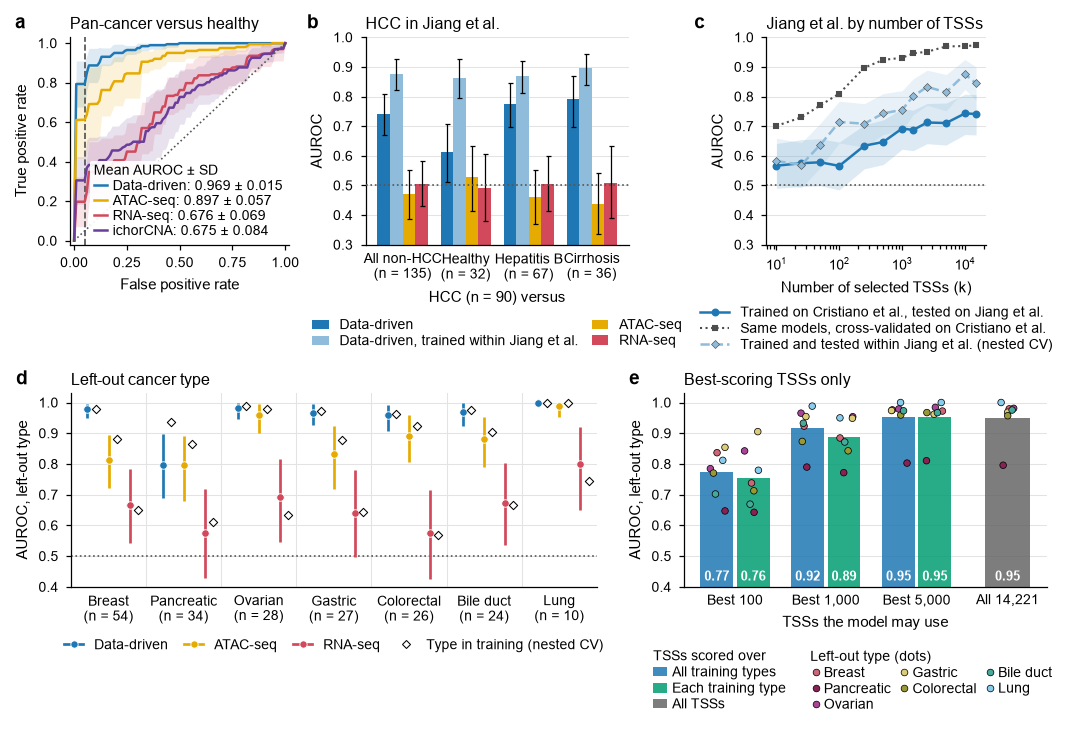

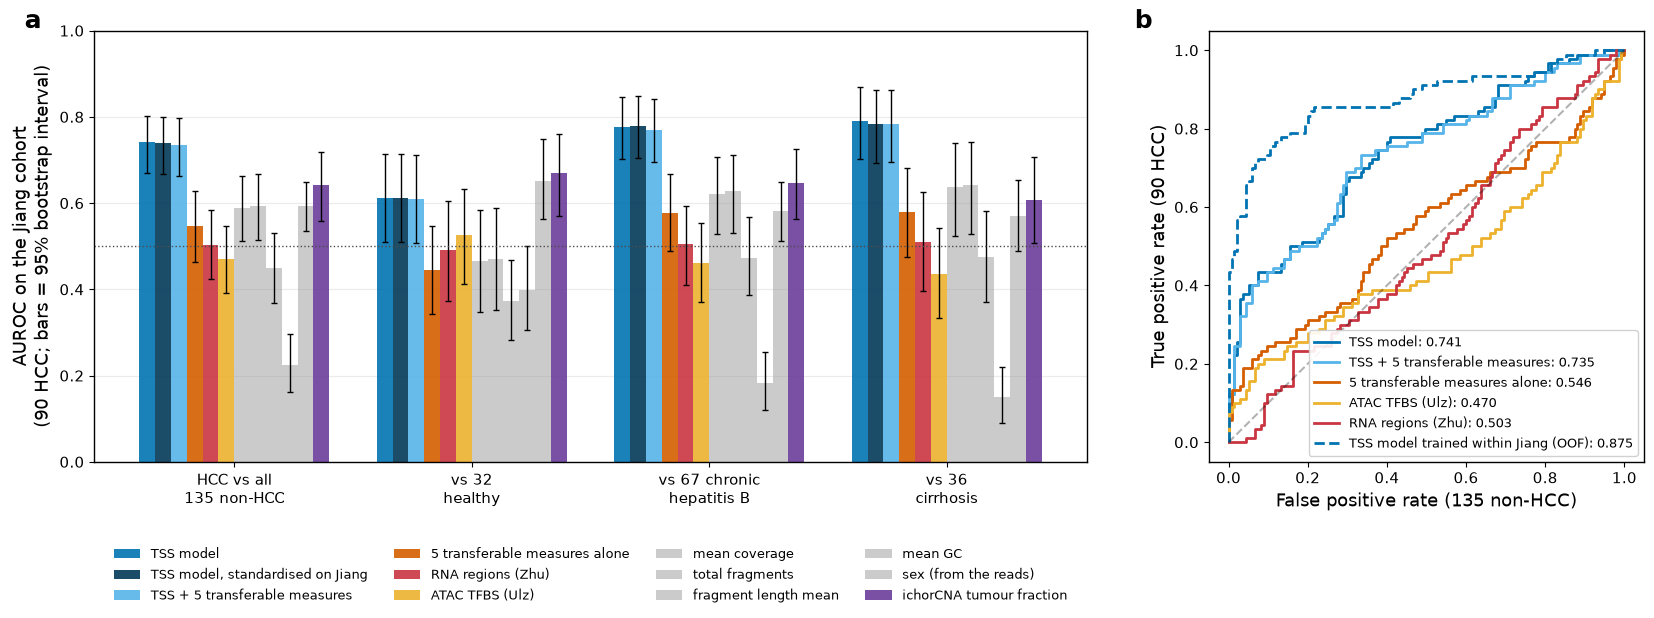

In [8]:
FIG_H, FIG_ROWS = 4.7, [1, 1]     # Figure 4, inches: with its caption and alt text it must fit the 232 mm text height


def _letters(pairs, x=-0.12, y=1.05):
    for ax, letter in pairs:
        ax.text(x, y, letter, transform=ax.transAxes, fontsize=18, fontweight="bold", va="top")


def _frame(axes):
    for ax in axes:
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
            spine.set_color("black")


# ---- Figure 4 (fig:pancan_generalization) --------------------------------------------------------------
# drawn at its printed size in the shared main-figure style (_figstyle.py); the style is applied only
# inside this block, so that Figure S16 below keeps its own look
with mpl.rc_context():
    fs.apply()
    fig = plt.figure(figsize=fs.size(height=FIG_H), layout="constrained")
    _top, _bot = fig.subfigures(2, 1, height_ratios=FIG_ROWS)
    axes = list(_top.subplots(1, 3, gridspec_kw={"width_ratios": [1, 1.2, 1]})) + \
        list(_bot.subplots(1, 2, gridspec_kw={"width_ratios": [1.45, 1]}))
    panel_a(axes[0])
    panel_jiang_bars(axes[1])
    panel_j(axes[2])
    panel_loco_auc(axes[3])
    panel_loco_rankings(axes[4])
    for ax, letter, title in zip(axes, "abcde", ["Pan-cancer versus healthy", "HCC in Jiang et al.",
                                                 "Jiang et al. by number of TSSs", "Left-out cancer type",
                                                 "Best-scoring TSSs only"]):
        fs.panel(ax, letter, title)
    fs.save(fig, out_path("fig4"))
    plt.show()

# ---- Figure S16 (Jiang detail) --------------------------------------------------------------
# two panels (panel_c, panel_g and panel_i are not drawn)
fig = plt.figure(figsize=(20, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1], wspace=0.28)
ax_a = fig.add_subplot(gs[0, :2])
ax_b = fig.add_subplot(gs[0, 2])
panel_s16_covariates(ax_a)
panel_s16_roc(ax_b)
_letters([(ax_a, "a")], x=-0.07)
_letters([(ax_b, "b")], x=-0.17)
_frame([ax_a, ax_b])
fig.savefig(out_path("figS16.png"), dpi=300, bbox_inches="tight")
fig.savefig(out_path("figS16.pdf"), bbox_inches="tight")
plt.show()

## Summary values

In [9]:
print("Panel a (manuscript: Data-driven 0.946 ± 0.032, ATAC 0.904 ± 0.048, "
      "RNA 0.715 ± 0.122, ichorCNA 0.620 ± 0.076):")
for method in ["data_driven", "atac", "rna", "ichorcna"]:
    df = pred5a[(pred5a["method"] == method) & pred5a["fold"].notna()]
    aucs = []
    for _, g in df.groupby("fold"):
        g = expand(g).dropna(subset=["score"])
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        aucs.append(auc(fpr, tpr))
    print(f"  {METHOD_LABELS[method]:<12} {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

print("\nPanel b/c (manuscript 5b legend: Data-driven 0.694, ATAC 0.680, RNA 0.536; "
      "5c bars, external-ROC operating point: 0.38 / 0.28 / 0.04):")
for method in ["dd", "atac", "rna"]:
    d = ext_rocs[method]
    op = frozen_ops[method]
    frozen = (f"frozen thr {op['threshold']:.3f}: sens {op['sens']:.2f} "
              f"[{op['sens_ci'][0]:.2f}-{op['sens_ci'][1]:.2f}] ({op['tp']}/{op['tp'] + op['fn']}), "
              f"spec {op['spec']:.2f} ({op['tn']}/{op['tn'] + op['fp']})"
              if op else f"frozen threshold n/a ({ext_cfg.loc[method, 'threshold_95spec_train_source']}"
                         f"{', proba degenerate' if ext_cfg.loc[method, 'proba_degenerate'] else ''})")
    print(f"  {METHOD_LABELS[method]:<12} AUC={d['auc']:.3f}  sens@95spec(ext ROC)={d['sens_95_ext']:.2f}  | {frozen}")
if "dd_jiang" in ext_rocs:
    d = ext_rocs["dd_jiang"]
    print(f"  {'DD (Jiang-trained)':<12} pooled OOF AUC={d['auc']:.3f}, outer folds {d['fold_mean']:.3f} ± {d['fold_std']:.3f}")

print("\nPanel h — HCC vs each Jiang comparison group, AUROC [participant bootstrap 95% CI]:")
hdr = f"  {'':<28}" + "".join(f"{lbl:>22}" for _, lbl in COMPARISONS)
print(hdr)
for m, res in pairwise.items():
    print(f"  {METHOD_LABELS[m]:<28}" + "".join(
        f"{res[g][0]:.3f} [{res[g][1]:.2f}-{res[g][2]:.2f}]".rjust(22) for g, _ in COMPARISONS))
print("  n controls:" + " " * 17 + "".join(f"{pairwise['dd'][g][3]:>22}" for g, _ in COMPARISONS))

print("\nPanel g — median predicted probability per subgroup (deployed data-driven model):")
print(ext[ext["method"] == "dd"].groupby("subgroup")["score"].agg(["count", "median", "mean"])
      .reindex(SUBGROUP_ORDER).round(3).to_string())

print("\nPanel j — per-k deployed models on Jiang (winner per k chosen on Cristiano training CV):")
print(kc[["mode", "n_genes", "feature", "classifier", "training_cv_auc", "external_auc", "per_sample_scores"]]
      .round(3).to_string(index=False))
for mode, g in kc.groupby("mode"):
    g = g.sort_values("n_genes")
    print(f"  {mode}: Spearman(k, external AUROC) = "
          f"{pd.Series(g['n_genes'].to_numpy()).corr(pd.Series(g['external_auc'].to_numpy()), method='spearman'):.2f}; "
          f"external {g['external_auc'].iloc[0]:.3f} (k={g['n_genes'].iloc[0]}) -> {g['external_auc'].iloc[-1]:.3f} "
          f"(k={g['n_genes'].iloc[-1]}); training CV {g['training_cv_auc'].iloc[0]:.3f} -> {g['training_cv_auc'].iloc[-1]:.3f}")
if HAVE_JIANG_KSWEEP:
    print("\nPanel j — trained within Jiang, fully nested selection per k:")
    print(jks[["k", "mean_test_auc", "std_test_auc", "oof_auc_pooled", "modal_feature", "modal_selection_type",
               "n_distinct_configs"]].round(3).to_string(index=False))
else:
    print("\nPanel j — Jiang k-sweep pending (reference line = E3 nested CV, k chosen per fold)")

print("\nPanels k/l — standardization mode of the deployed data-driven model on Jiang:")
if HAVE_CLINICAL:
    print(modes_cfg[["mode", "feature", "n_genes", "classifier", "train_cv_auc", "external_auc",
                     "threshold_95spec_train", "threshold_95spec_train_source"]].round(3).to_string(index=False))
    for m in ["pipeline", "clinical"]:
        res = pairwise_aucs(modes_pred[modes_pred["mode"] == m], "score_for_roc")
        print(f"  {m:<10}" + "".join(f"{res[g][0]:.3f} [{res[g][1]:.2f}-{res[g][2]:.2f}]".rjust(22) for g, _ in COMPARISONS))
else:
    print("  clinical-mode revision run pending; pipeline mode only:",
          modes_cfg[["mode", "feature", "n_genes", "classifier", "external_auc"]].round(3).to_dict("records"))

print("\nPanels d-f, leave-one-cancer-type-out (the within-dataset panels of the submitted manuscript are removed):")
print(loco_type[["label", "n_cancer", "feature", "classifier", "n_tss", "auc", "auc_lo", "auc_hi", "auc_in_training",
                 "tp", "fn", "tn", "fp"]].round(3).to_string(index=False))
print("panel f, mean AUROC over the seven types (fixed model; pooled vs consensus ranking; all TSSs):")
print(loco_rank.groupby(["ranking", "k"])["auc"].mean().unstack(0).round(3).to_string())
print("search winner per number of TSSs (not drawn):", loco_ks.groupby("k")["auc"].mean().round(3).to_dict())


Panel a (manuscript: Data-driven 0.946 ± 0.032, ATAC 0.904 ± 0.048, RNA 0.715 ± 0.122, ichorCNA 0.620 ± 0.076):
  Data-driven  0.969 ± 0.015
  ATAC         0.897 ± 0.057
  RNA          0.676 ± 0.069
  ichorCNA     0.675 ± 0.084

Panel b/c (manuscript 5b legend: Data-driven 0.694, ATAC 0.680, RNA 0.536; 5c bars, external-ROC operating point: 0.38 / 0.28 / 0.04):
  Data-driven  AUC=0.741  sens@95spec(ext ROC)=0.38  | frozen thr 0.445: sens 0.43 [0.33-0.54] (39/90), spec 0.89 (120/135)
  ATAC         AUC=0.470  sens@95spec(ext ROC)=0.13  | frozen thr 0.788: sens 0.82 [0.73-0.89] (74/90), spec 0.10 (14/135)
  RNA          AUC=0.503  sens@95spec(ext ROC)=0.00  | frozen thr 0.894: sens 0.23 [0.15-0.33] (21/90), spec 0.84 (113/135)
  DD (Jiang-trained) pooled OOF AUC=0.875, outer folds 0.902 ± 0.076

Panel h — HCC vs each Jiang comparison group, AUROC [participant bootstrap 95% CI]:
                                          vs healthy        vs chronic HBV          vs cirrhosis        vs all 

  pipeline       0.612 [0.51-0.71]     0.776 [0.70-0.85]     0.791 [0.70-0.87]     0.741 [0.67-0.81]


  clinical       0.611 [0.51-0.71]     0.778 [0.70-0.85]     0.782 [0.69-0.86]     0.740 [0.67-0.81]

Panels d-f, leave-one-cancer-type-out (the within-dataset panels of the submitted manuscript are removed):
     label  n_cancer      feature          classifier  n_tss   auc  auc_lo  auc_hi  auc_in_training  tp  fn  tn  fp
    Breast        54 griffin_diff Logistic Regression  15000 0.979   0.951   0.996            0.978  44  10  33   1
Pancreatic        34 griffin_diff Logistic Regression  15000 0.798   0.689   0.896            0.935  10  24  32   2
   Ovarian        28 griffin_diff Logistic Regression  15000 0.982   0.947   1.000            0.987  25   3  32   2
   Gastric        27 griffin_diff Logistic Regression  15000 0.967   0.926   0.996            0.973  22   5  32   2
Colorectal        26 griffin_diff Logistic Regression  15000 0.958   0.906   0.992            0.962  19   7  32   2
 Bile duct        24 griffin_diff Logistic Regression  15000 0.968   0.924   0.998            0